# Person B — Week 1 Deep Learning Exploration

This notebook explores the UCI HAR sensor signals, compares walking
and lying examples, and proposes a 1D CNN for recognizing six activities.

Data are loaded through the team's shared src/har_data.py loader.
The official training set is used for this exploration.

In [3]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

repo = Path.cwd()
if repo.name == "notebooks":
    repo = repo.parent

sys.path.insert(0, str(repo))

from src.har_data import load_raw_signals

X_raw, y_raw = load_raw_signals("train")

print("Signal shape:", X_raw.shape)
print("Label shape:", y_raw.shape)
print("Activity labels:", np.unique(y_raw))

Signal shape: (7352, 128, 9)
Label shape: (7352,)
Activity labels: [1 2 3 4 5 6]


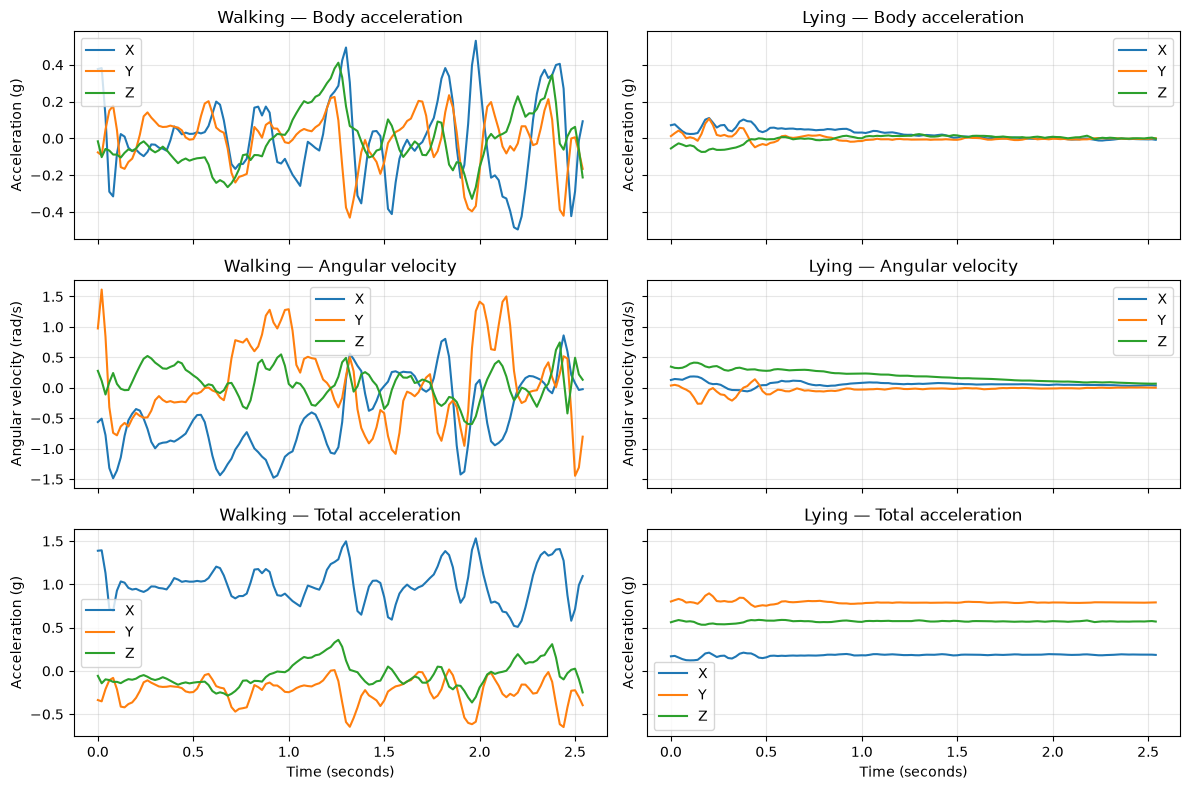

In [4]:
time = np.arange(X_raw.shape[1]) / 50
activities = {1: "Walking", 6: "Lying"}
signal_groups = [
    ("Body acceleration", 0, "Acceleration (g)"),
    ("Angular velocity", 3, "Angular velocity (rad/s)"),
    ("Total acceleration", 6, "Acceleration (g)"),
]

fig, axes = plt.subplots(
    3, 2, figsize=(12, 8), sharex=True, sharey="row"
)

for column, (label, activity) in enumerate(activities.items()):
    window_index = np.flatnonzero(y_raw == label)[0]

    for row, (signal, start, unit) in enumerate(signal_groups):
        ax = axes[row, column]

        for offset, axis_name in enumerate(["X", "Y", "Z"]):
            ax.plot(
                time,
                X_raw[window_index, :, start + offset],
                label=axis_name,
            )

        ax.set_title(f"{activity} — {signal}")
        ax.set_ylabel(unit)
        ax.grid(alpha=0.3)
        ax.legend()

        if row == 2:
            ax.set_xlabel("Time (seconds)")

fig.tight_layout()
(repo / "figures").mkdir(exist_ok=True)
fig.savefig(repo / "figures" / "B_raw_signal_examples.png", dpi=160)
plt.show()

## Observations from the signal examples

The walking window shows larger fluctuations in body acceleration and angular velocity than the lying window. During lying, body acceleration stays close to zero and total acceleration remains relatively steady because it includes gravity. These two windows illustrate patterns that a classifier could learn. Additional windows and participants are needed to assess how consistently those patterns occur.

The loader returns preprocessed inertial windows from the UCI HAR dataset. Although these are called raw signals in our project, they have already been filtered and divided into overlapping windows.

## Proposed deep learning algorithm

We propose a one-dimensional convolutional neural network (1D CNN) to classify six activities from the sensor sequences. Each input window has shape `(128, 9)`, representing 128 time steps sampled at 50 Hz across nine channels. The channels contain X, Y, and Z measurements for body acceleration, angular velocity, and total acceleration. Each window covers 2.56 seconds.

Our initial architecture will use a Conv1D layer with 32 filters, a kernel size of 5, same padding, and ReLU activation, followed by max pooling with a pool size of 2. A second Conv1D layer with 64 filters, a kernel size of 5, same padding, and ReLU activation will learn additional temporal patterns. Global average pooling will summarize the sequence, followed by dropout at a rate of 0.3 and a dense softmax layer with six outputs.

The proposed shape progression is `(128, 9) → (128, 32) → (64, 32) → (64, 64) → (64,) → (6,)`. During training, the input will include a batch dimension, giving shape `(batch_size, 128, 9)`.

We will train with Adam and sparse categorical cross-entropy, converting activity labels from 1–6 to 0–5. Channel standardization will use statistics calculated only from the training portion of each fold. Validation will hold out entire participants using GroupKFold. Early stopping will monitor validation loss, and the official test participants will be reserved for final evaluation. We will report accuracy and macro F1 and save a confusion matrix.

## Related course topics

This approach connects supervised multiclass classification with neural networks and learned representations. Convolutional filters learn local patterns over time, while backpropagation and gradient-based optimization adjust their weights. Pooling reduces the sequence representation, and dropout and early stopping help control overfitting.

Hyperparameters include the number of filters, kernel size, learning rate, batch size, and dropout rate. Participant-based validation evaluates generalization to new people. Comparing the CNN with classical models using the 561 engineered features will help assess whether learning from sensor sequences improves recognition enough to justify its computational cost.

## Week 1 status

The raw training signals have been loaded, walking and lying examples have been plotted, and an initial CNN architecture and proposal sections have been drafted. Model training and performance evaluation are planned for subsequent work.